# Project B: 2D Radiation Transport in Tissue

In [609]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from dataclasses import dataclass

### Geometry

The overall rectangle is made up of water

Within the water rectangle are two smaller rectangles of one air pocket and one bone piece

In [610]:
# Overall water rectangle
water_rect = {
    'start_x' : 0,
    'start_y': 0,
    'length': 200,
    'height': 300,
    'label': 'Water',
    'color': 'lightblue',
    'fill': True,
}

air_rect = {
    'start_x' : 62.5,
    'start_y': 165,
    'length': 75,
    'height': 75,
    'label': 'Air',
    'color': 'gainsboro',
    'fill': True
}

bone_rect = {
    'start_x' : 62.5,
    'start_y': 65,
    'length': 75,
    'height': 75,
    'label': 'Bone',
    'color': 'grey',
    'fill': True
}

rects = [water_rect, air_rect, bone_rect]

### Single object test

$\mu = \rho(\frac{\mu}{\rho_{H2O}})$. For a photon of 1 MeV, $\frac{\mu}{\rho}=7.702e-2$ cm^2/g, and $\rho=1$ g/cm^3. We sample the distance traveled from an inverse exponential distribution, $$s=-\frac{ln(u)}{\mu}$$

In [611]:
xray_energy = 1
mu_p_h20 = 7.072e-2
p = 1
mu_water = mu_p_h20 * 1 #cm^-1
average_travelled = 1/mu_water

# randomly choose a depth number s.t distribution gives an exponential decay
# so I sample the linear attenuation of 

# inverse transform sampling equation for an exponential distribution
nphotons = 10000
u = np.random.rand(nphotons)
s = -np.log(u)/mu_water
average_sampled = float(np.mean(s))

print(f"Average analytic traveled: {average_travelled:0.5f}")
print(f"Average sample traveled: {average_sampled:0.5f}")

# entering height of the photon
y = np.random.randint(0,300,nphotons)

Average analytic traveled: 14.14027
Average sample traveled: 14.46481


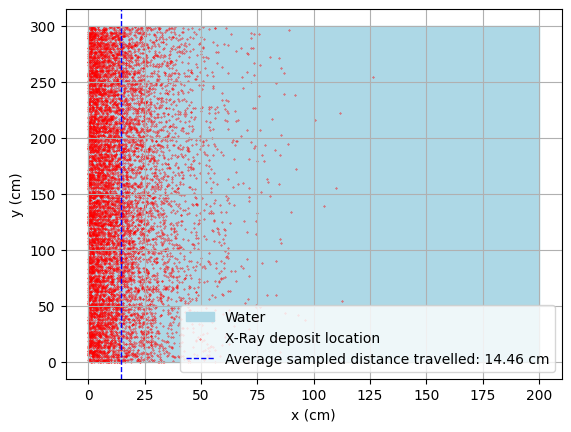

In [612]:
fig, ax = plt.subplots()


start_x = water_rect['start_x']
start_y = water_rect['start_y']
length = water_rect['length']
height = water_rect['height']
label_legend = water_rect['label']
color = water_rect['color']
fill_bool = water_rect['fill']

ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))
ax.scatter(s,y, s=0.1, color = "red", label = "X-Ray deposit location")
ax.axvline(average_sampled, color='blue', linestyle='--', linewidth=1, label=f'Average sampled distance travelled: {np.mean(s):0.2f} cm')

ax.grid(True)
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
plt.legend()
plt.show()

## Fitting mass attenuation coefficients as functions of photon energy

### Water

Obtained from https://physics.nist.gov/PhysRefData/Xcom/html/xcom1.html "H2O"

In [613]:
# Data cleaning
# Data cleaning
data = np.loadtxt("./datasets/water-photon-attenuation.txt", skiprows=2)
data = data.T

photon_energy = data[0]
compton = data[1]
pe = data[2]
pairprod = data[3]
total = data[4]

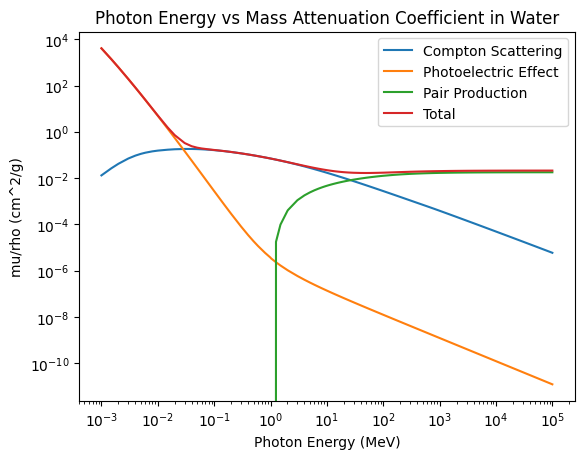

In [614]:
plt.plot(photon_energy, compton, label = "Compton Scattering")
plt.plot(photon_energy, pe, label = "Photoelectric Effect")
plt.plot(photon_energy, pairprod, label = "Pair Production")
plt.plot(photon_energy, total, label = "Total")
plt.title("Photon Energy vs Mass Attenuation Coefficient in Water")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho (cm^2/g)")
plt.legend()
plt.xscale('log')
plt.yscale('log')

#### Compton Scattering

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/215499188.py:3: RankWarning: Polyfit may be poorly conditioned
  waterCompCoe = np.polyfit(log_energy, log_attenuation, 50)


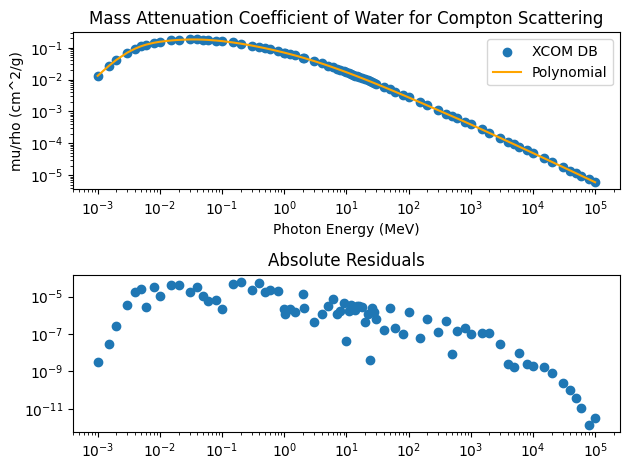

In [615]:
log_energy = np.log10(photon_energy)
log_attenuation = np.log10(compton)
waterCompCoe = np.polyfit(log_energy, log_attenuation, 50)

def waterCompAtte(energy):
    attenuation = 10 ** np.polyval(waterCompCoe, np.log10(energy))
    return attenuation

compton_fit = waterCompAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(compton_fit - compton)

ax[0].scatter(photon_energy, compton, label = "XCOM DB")
ax[0].plot(photon_energy, compton_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Water for Compton Scattering")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

#### Photoelectric Effect

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2780359798.py:3: RankWarning: Polyfit may be poorly conditioned
  waterPeCoe = np.polyfit(log_energy, log_attenuation, 50)


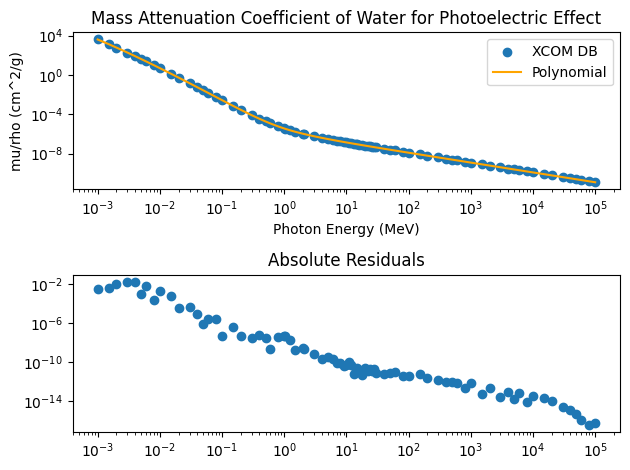

In [616]:
log_energy = np.log10(photon_energy)
log_attenuation = np.log10(pe)
waterPeCoe = np.polyfit(log_energy, log_attenuation, 50)

def waterPeAtte(energy):
    attenuation = 10 ** np.polyval(waterPeCoe, np.log10(energy))
    return attenuation

pe_fit = waterPeAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(pe_fit - pe)

ax[0].scatter(photon_energy, pe, label = "XCOM DB")
ax[0].plot(photon_energy, pe_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Water for Photoelectric Effect")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

#### Pair Production

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/1530345234.py:5: RankWarning: Polyfit may be poorly conditioned
  waterPairProdCoe = np.polyfit(log_energy, log_attenuation, 50)


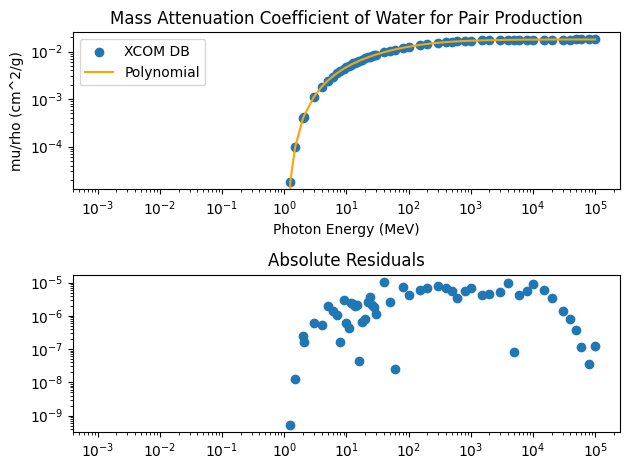

In [617]:
positive = pairprod > 0

log_energy = np.log10(photon_energy[positive])
log_attenuation = np.log10(pairprod[positive])
waterPairProdCoe = np.polyfit(log_energy, log_attenuation, 50)

def waterPairProdAtte(energy):
    if isinstance(energy, (int, float)):
        attenuation = 10 ** np.polyval(waterPairProdCoe, np.log10(energy))
        return attenuation
    else:
        attenuation = np.zeros_like(energy, dtype=float)
        above_threshold = energy > 1.022
        attenuation[above_threshold] = 10 ** np.polyval(waterPairProdCoe, np.log10(energy[above_threshold]))
        return attenuation

pairprod_fit = waterPairProdAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(pairprod_fit - pairprod)

ax[0].scatter(photon_energy, pairprod, label = "XCOM DB")
ax[0].plot(photon_energy, pairprod_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Water for Pair Production")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

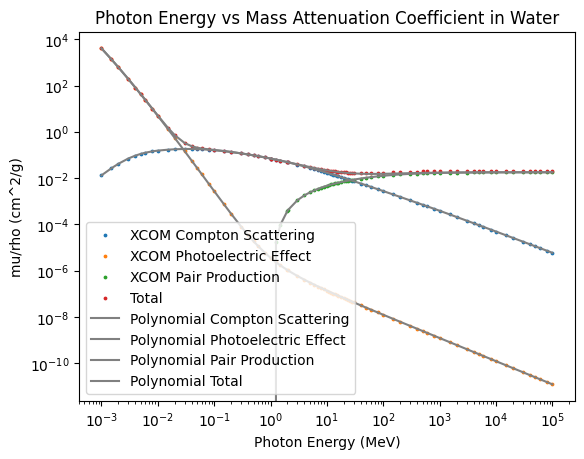

In [618]:
plt.scatter(photon_energy, compton, label = "XCOM Compton Scattering", s = 3)
plt.scatter(photon_energy, pe, label = "XCOM Photoelectric Effect", s = 3)
plt.scatter(photon_energy, pairprod, label = "XCOM Pair Production", s = 3)
plt.scatter(photon_energy, total, label = "Total", s = 3)

plt.plot(photon_energy, waterCompAtte(photon_energy), label = "Polynomial Compton Scattering", color = 'gray')
plt.plot(photon_energy, waterPeAtte(photon_energy), label = "Polynomial Photoelectric Effect", color = 'gray')
plt.plot(photon_energy, waterPairProdAtte(photon_energy), label = "Polynomial Pair Production", color = 'gray')
plt.plot(photon_energy, waterCompAtte(photon_energy) + waterPeAtte(photon_energy) + waterPairProdAtte(photon_energy), label = "Polynomial Total", color = 'gray')

plt.title("Photon Energy vs Mass Attenuation Coefficient in Water")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho (cm^2/g)")
plt.legend()
plt.xscale('log')
plt.yscale('log')

### Bone
Obtained from https://physics.nist.gov/cgi-bin/Xcom/xcom3_3

Exact composition of cortical bone obtained from: https://physics.nist.gov/PhysRefData/XrayMassCoef/tab2.html

In [633]:
# Data cleaning
# Data cleaning
data = np.loadtxt("./datasets/bone-photon-attenuation.txt", skiprows=2)
data = data.T

photon_energy = data[0]
compton = data[1]
pe = data[2]
pairprod = data[3]
total = data[4]

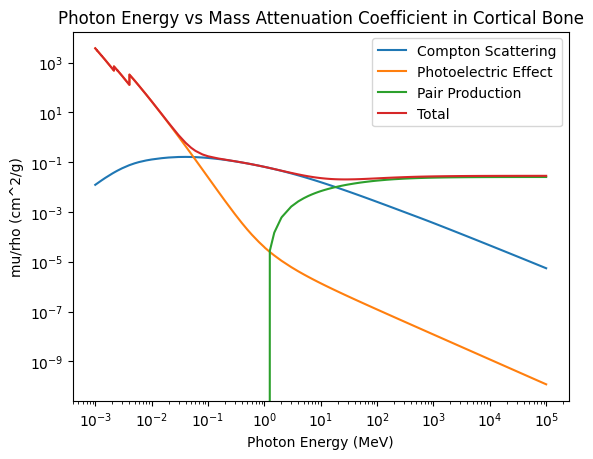

In [634]:
plt.plot(photon_energy, compton, label = "Compton Scattering")
plt.plot(photon_energy, pe, label = "Photoelectric Effect")
plt.plot(photon_energy, pairprod, label = "Pair Production")
plt.plot(photon_energy, total, label = "Total")
plt.title("Photon Energy vs Mass Attenuation Coefficient in Cortical Bone")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho (cm^2/g)")
plt.legend()
plt.xscale('log')
plt.yscale('log')

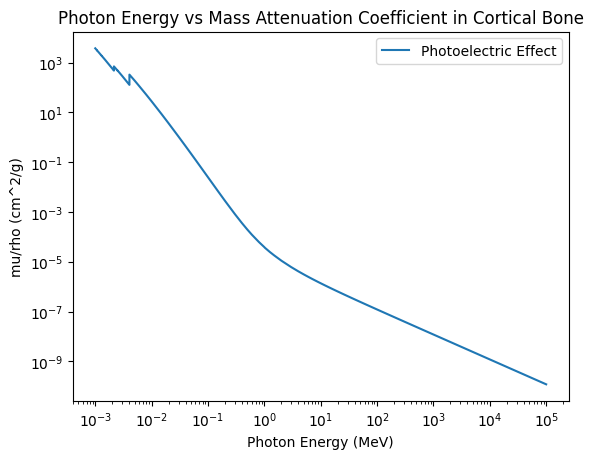

In [621]:
plt.plot(photon_energy, pe, label = "Photoelectric Effect")
plt.title("Photon Energy vs Mass Attenuation Coefficient in Cortical Bone")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho (cm^2/g)")
plt.legend()
plt.xscale('log')
plt.yscale('log')

#### Compton Scattering

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2836621023.py:3: RankWarning: Polyfit may be poorly conditioned
  boneCompCoe = np.polyfit(log_energy, log_attenuation, 50)


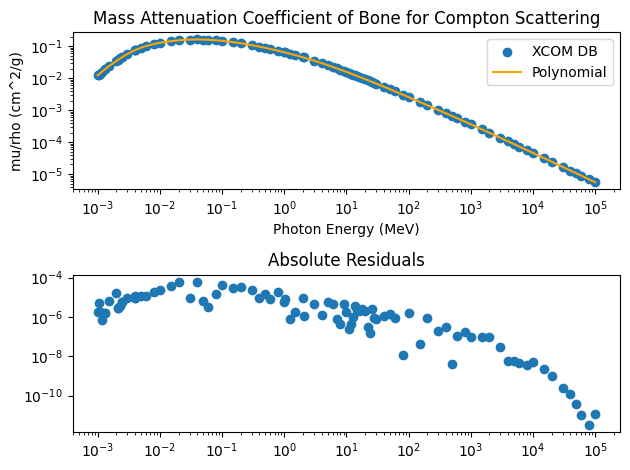

In [622]:
log_energy = np.log10(photon_energy)
log_attenuation = np.log10(compton)
boneCompCoe = np.polyfit(log_energy, log_attenuation, 50)

def boneCompAtte(energy):
    attenuation = 10 ** np.polyval(boneCompCoe, np.log10(energy))
    return attenuation

compton_fit = boneCompAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(compton_fit - compton)

ax[0].scatter(photon_energy, compton, label = "XCOM DB")
ax[0].plot(photon_energy, compton_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Bone for Compton Scattering")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

#### Photoelectric Effect

In [623]:
# Find adjacent duplicate energies, which mark the absorption edges.
edge_rows = np.flatnonzero(np.diff(photon_energy) == 0)
edge_energies = photon_energy[edge_rows]
cuts = np.r_[0, edge_rows + 1, len(photon_energy)]

# Fit each interval in log-log space.
pe_coefficients = []
for start, stop in zip(cuts[:-1], cuts[1:]):
    x = photon_energy[start:stop]
    y = pe[start:stop]

    degree = 5
    coeff = np.polyfit(np.log10(x), np.log10(y), degree)
    pe_coefficients.append(coeff)


def bonePeAtte(energy):
    values = np.asarray(energy, dtype=float)
    is_scalar = values.ndim == 0
    shape = values.shape
    flat = values.reshape(-1)

    if np.any(~np.isfinite(flat)) or np.any(flat <= 0):
        raise ValueError("Energy values must be finite and positive.")
    if np.any(flat < photon_energy.min()) or np.any(flat > photon_energy.max()):
        raise ValueError("Energy is outside the range covered by the data.")

    # At an edge, choose the post-edge interval.
    intervals = np.searchsorted(edge_energies, flat, side="right")
    result = np.empty_like(flat)

    for i, coeff in enumerate(pe_coefficients):
        selected = intervals == i
        result[selected] = 10 ** np.polyval(coeff, np.log10(flat[selected]))

    if is_scalar:
        return float(result[0])
    return result.reshape(shape)

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2285368016.py:13: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(np.log10(x), np.log10(y), degree)
/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2285368016.py:13: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(np.log10(x), np.log10(y), degree)
/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2285368016.py:13: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(np.log10(x), np.log10(y), degree)
/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2285368016.py:13: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(np.log10(x), np.log10(y), degree)
/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/2285368016.py:13: RankWarning: Polyfit may be poorly conditioned
  coeff = np.polyfit(np.log10(x), np.log10(y), degree)


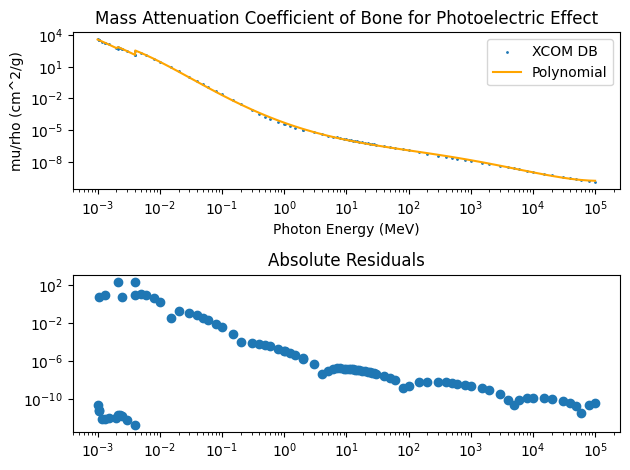

In [624]:
pe_fit = bonePeAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(pe_fit - pe)

ax[0].scatter(photon_energy, pe, label = "XCOM DB", s = 1)
ax[0].plot(photon_energy, pe_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Bone for Photoelectric Effect")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

#### Pair Production

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/3981374177.py:5: RankWarning: Polyfit may be poorly conditioned
  bonePairProdCoe = np.polyfit(log_energy, log_attenuation, 50)


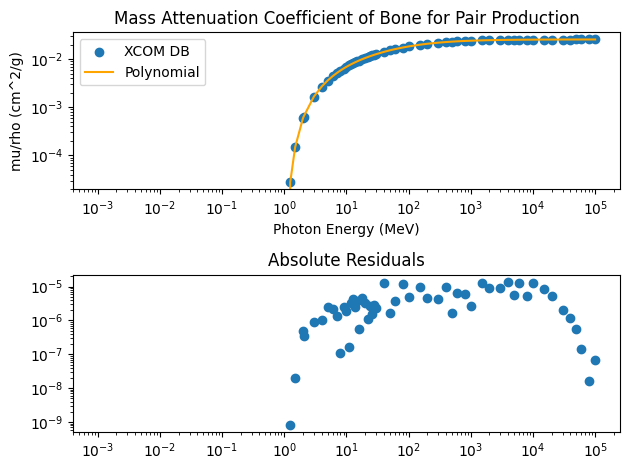

In [625]:
positive = pairprod > 0

log_energy = np.log10(photon_energy[positive])
log_attenuation = np.log10(pairprod[positive])
bonePairProdCoe = np.polyfit(log_energy, log_attenuation, 50)

def bonePairProdAtte(energy):
    if isinstance(energy, (int, float)):
        attenuation = 10 ** np.polyval(bonePairProdCoe, np.log10(energy))
        return attenuation
    else:
        attenuation = np.zeros_like(energy, dtype=float)
        above_threshold = energy > 1.022
        attenuation[above_threshold] = 10 ** np.polyval(bonePairProdCoe, np.log10(energy[above_threshold]))
        return attenuation

pairprod_fit = bonePairProdAtte(photon_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(pairprod_fit - pairprod)

ax[0].scatter(photon_energy, pairprod, label = "XCOM DB")
ax[0].plot(photon_energy, pairprod_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Attenuation Coefficient of Bone for Pair Production")
ax[0].set_xlabel("Photon Energy (MeV)")
ax[0].set_ylabel("mu/rho (cm^2/g)")

ax[1].scatter(photon_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

### Total Fit vs XCOM DB

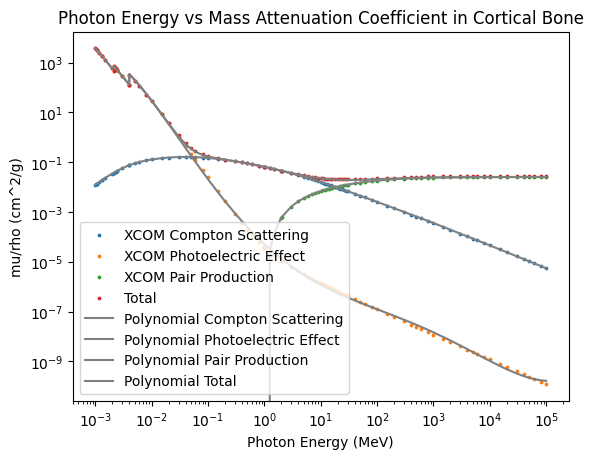

In [626]:
plt.scatter(photon_energy, compton, label = "XCOM Compton Scattering", s = 3)
plt.scatter(photon_energy, pe, label = "XCOM Photoelectric Effect", s = 3)
plt.scatter(photon_energy, pairprod, label = "XCOM Pair Production", s = 3)
plt.scatter(photon_energy, total, label = "Total", s = 3)

plt.plot(photon_energy, boneCompAtte(photon_energy), label = "Polynomial Compton Scattering", color = 'gray')
plt.plot(photon_energy, bonePeAtte(photon_energy), label = "Polynomial Photoelectric Effect", color = 'gray')
plt.plot(photon_energy, bonePairProdAtte(photon_energy), label = "Polynomial Pair Production", color = 'gray')
plt.plot(photon_energy, boneCompAtte(photon_energy) + bonePeAtte(photon_energy) + bonePairProdAtte(photon_energy), label = "Polynomial Total", color = 'gray')

plt.title("Photon Energy vs Mass Attenuation Coefficient in Cortical Bone")
plt.xlabel("Photon Energy (MeV)")
plt.ylabel("mu/rho (cm^2/g)")
plt.legend()
plt.xscale('log')
plt.yscale('log')

## Mass Stopping Power (Electrons)

### Water

https://physics.nist.gov/PhysRefData/Star/Text/ESTAR.html

Text(0, 0.5, 'Mass Stopping Power (MeV cm^2/g)')

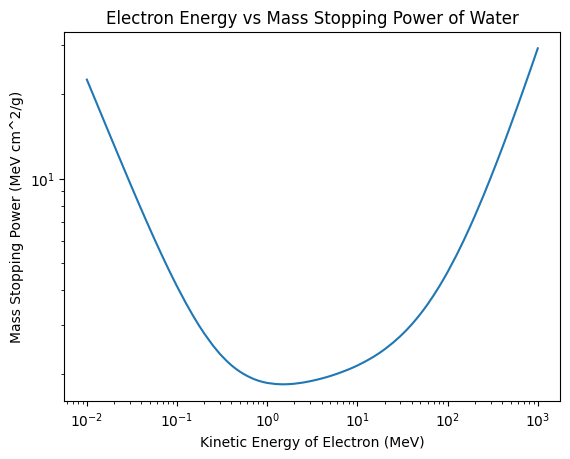

In [627]:
# Data cleaning
data = np.loadtxt("./datasets/water-electron-stopping.txt", skiprows=3)
data = data.T

electron_energy = data[0]
total = data[1]

plt.plot(electron_energy, total)
plt.xscale('log')
plt.yscale('log')
plt.title("Electron Energy vs Mass Stopping Power of Water")
plt.xlabel("Kinetic Energy of Electron (MeV)")
plt.ylabel("Mass Stopping Power (MeV cm^2/g)")

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/334066152.py:3: RankWarning: Polyfit may be poorly conditioned
  waterStopCoe = np.polyfit(log_energy, log_stopping, 50)


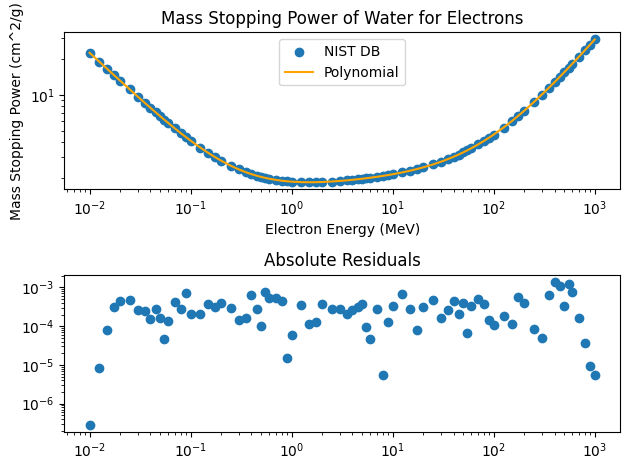

In [628]:
log_energy = np.log10(electron_energy)
log_stopping = np.log10(total)
waterStopCoe = np.polyfit(log_energy, log_stopping, 50)

def waterStopping(energy):
    mass_stopping = 10 ** np.polyval(waterStopCoe, np.log10(energy))
    return mass_stopping

water_stopping_fit = waterStopping(electron_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(water_stopping_fit - total)

ax[0].scatter(electron_energy, total, label = "NIST DB")
ax[0].plot(electron_energy, water_stopping_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Stopping Power of Water for Electrons")
ax[0].set_xlabel("Electron Energy (MeV)")
ax[0].set_ylabel("Mass Stopping Power (cm^2/g)")

ax[1].scatter(electron_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

### Bone

https://physics.nist.gov/cgi-bin/Star/e_table.pl

Text(0, 0.5, 'Mass Stopping Power (MeV cm^2/g)')

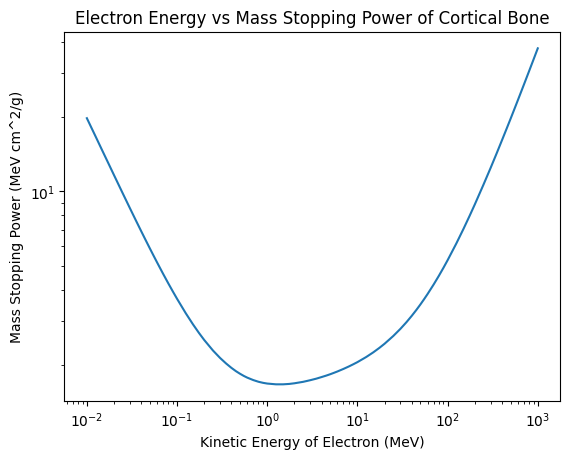

In [629]:
# Data cleaning
data = np.loadtxt("./datasets/bone-electron-stopping.txt", skiprows=3)
data = data.T

electron_energy = data[0]
total = data[1]

plt.plot(electron_energy, total)
plt.xscale('log')
plt.yscale('log')
plt.title("Electron Energy vs Mass Stopping Power of Cortical Bone")
plt.xlabel("Kinetic Energy of Electron (MeV)")
plt.ylabel("Mass Stopping Power (MeV cm^2/g)")

/var/folders/y6/_vtfk1x97_g2hvv8pf8qkfgr0000gn/T/ipykernel_5307/3946670361.py:3: RankWarning: Polyfit may be poorly conditioned
  boneStopCoe = np.polyfit(log_energy, log_stopping, 50)


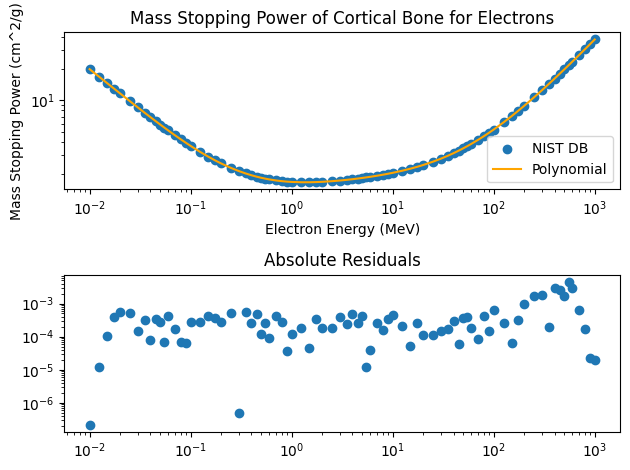

In [630]:
log_energy = np.log10(electron_energy)
log_stopping = np.log10(total)
boneStopCoe = np.polyfit(log_energy, log_stopping, 50)

def boneStopping(energy):
    mass_stopping = 10 ** np.polyval(boneStopCoe, np.log10(energy))
    return mass_stopping

bone_stopping_fit = boneStopping(electron_energy)

fig, ax = plt.subplots(2,1)
residuals = np.abs(bone_stopping_fit - total)

ax[0].scatter(electron_energy, total, label = "NIST DB")
ax[0].plot(electron_energy, bone_stopping_fit, label = "Polynomial", color = "orange")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()
ax[0].set_title("Mass Stopping Power of Cortical Bone for Electrons")
ax[0].set_xlabel("Electron Energy (MeV)")
ax[0].set_ylabel("Mass Stopping Power (cm^2/g)")

ax[1].scatter(electron_energy, residuals)
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].set_title("Absolute Residuals")

fig.tight_layout()

### Particle Class

In [631]:
@dataclass
class Particle:
    ptype: str
    pos: np.ndarray # (2,)
    dir: np.ndarray # (2,)
    energy: float   # MeV
    active: bool    # Deposited or not

### Adding bone and air

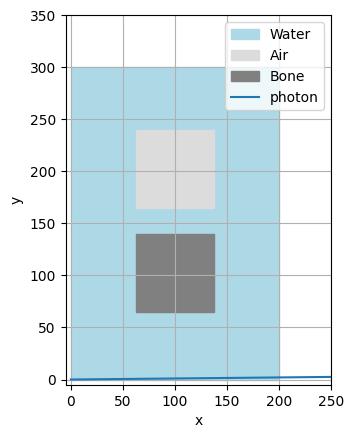

In [632]:
fig, ax = plt.subplots()

for rectangle in rects:
    start_x = rectangle['start_x']
    start_y = rectangle['start_y']
    length = rectangle['length']
    height = rectangle['height']
    label_legend = rectangle['label']
    color = rectangle['color']
    fill_bool = rectangle['fill']
    ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))


photon1 = np.array([0, 0, 150, 0])
time_array = np.linspace(0,100,1000)
x = 0.1*time_array
plt.plot(x, label = "photon")


ax.set_aspect("equal")
ax.set_xlim(-5, 250)
ax.set_ylim(-5, 350)
ax.grid(True)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.legend()
plt.show()